# Partie 2 — Approche Big Data (Hadoop / Apache Spark) : Analyse & Prédiction Distribuée des Mouvements de Cotes de Football (2018–2026)

**Projet :** ARMEN ASATYRAN 5A Foundation of Big Data — Étude Comparative Small Data vs Big Data
**Dataset :** `archangel0x01/football-odds-movements-2018-2026` (**37 345 126 lignes** réparties sur 5 tables transactionnelles et événementielles)  
**Stack technologique :** Écosystème Hadoop / Stockage orienté colonnes **Apache Parquet** / **Apache Spark 4.3.0 (PySpark SQL & MLlib)**

---

## Objectif de l'étude Big Data

Contrairement à la **Partie 1 (Approche Small Data)** où un jeu de données de quelques centaines de lignes tenait intégralement dans la mémoire vive d'un processus unique (`pandas` + `scikit-learn`), cette **Partie 2** traite une volumétrie **Big Data de plus de 37,3 millions d'enregistrements** (~2,54 Go en CSV brut) retraçant l'historique *tick-by-tick* des mouvements de cotes de paris sportifs (1X2, Asian Handicap, Over/Under) sur **63 597 matchs de football** à travers le monde entre 2018 et 2026.

Pour passer à l'échelle (*scalability*) sans goulet d'étranglement mémoire (*Out-Of-Memory*), nous déployons une architecture **Hadoop / Apache Spark** complète structurée en **7 étapes** :
1. **Architecture Big Data & Data Ingestion (Hadoop / Spark)** : Comparaison du format ligne (CSV) vs colonnaire distribué (**Apache Parquet**), initialisation de la `SparkSession`, lecture distribuée des **37,3M de lignes** et analyse du **DAG / Catalyst Optimizer** (*Lazy Evaluation*, *Predicate Pushdown*, *Column Pruning*).
2. **EDA Distribuée (Spark SQL & DataFrames)** : Requêtes distribuées sur plusieurs millions de lignes, agrégations en cluster et réduction vers le *Driver* (`.toPandas()`) uniquement sur les résultats condensés pour la visualisation.
3. **Prétraitement Distribué (PySpark)** : Nettoyage à grande échelle, filtrage des valeurs aberrantes/manquantes et construction de la cible multiclasse (`Home Win`, `Draw`, `Away Win`).
4. **Transformation & Feature Engineering (Spark ML Pipeline)** : Agrégations distribuées *MapReduce/Spark* des 11,6M de mouvements 1X2 et des 251k cotes de clôture au niveau `match_id`, création de variables métier financières (marge *overround*, dérive d'ouverture/clôture *odds drift*, volatilité *tick-by-tick*) et assemblage dans un `Pipeline` Spark ML **sans fuite de données (*Zero Data Leakage*)**.
5. **Machine Learning Distribué (Spark MLlib)** : Partitionnement distribué mis en cache (`.cache()`) et entraînement parallèle de 2 algorithmes distribués (`LogisticRegression` et `RandomForestClassifier`).
6. **Évaluation (EVAL — Spark MLlib)** : Évaluation multiclasse distribuée (`Accuracy`, `F1-Score`, `Weighted Precision`, `Weighted Recall`), matrice de confusion et analyse de l'importance des variables.
7. **Déploiement Big Data & Préparation GitHub** : Persistance native distribuée du modèle Spark ML (`models_spark/football_rf_model`) et export de la table de features au format standard Hadoop Parquet (`data_spark/football_features.parquet`).

---
## 1. Architecture Big Data & Data Ingestion (Hadoop / Spark)

### 1.1 Concepts fondamentaux de l'architecture Hadoop & Apache Spark

Lorsqu'un jeu de données dépasse plusieurs dizaines de millions de lignes (plusieurs gigaoctets à téraoctets), les outils monolithiques comme `pandas` se heurtent à trois limites physiques :
1. **Limite de la RAM (Memory Wall)** : `pandas` charge les structures en mémoire contiguë et multiplie souvent par 3 à 5 l'empreinte mémoire d'un fichier CSV lors du parsing.
2. **Goulet d'étranglement I/O disque** : Lire séquentiellement des fichiers CSV ligne par ligne impose de parser l'intégralité des colonnes et des caractères texte, même pour une requête n'utilisant que 2 colonnes sur 25.
3. **Exécution mono-thread (GIL Python)** : Les transformations classiques ne tirent pas parti du parallélisme multi-cœurs ou multi-nœuds.

L'écosystème **Hadoop / Spark** résout ces trois problèmes grâce à :
- **HDFS (Hadoop Distributed File System) & Stockage Orienté Colonnes (Apache Parquet)** :
  - Contrairement au format CSV (stockage par **lignes**), **Apache Parquet** stocke les données par **blocs de lignes (*Row Groups*) divisés en colonnes (*Column Chunks*)**.
  - **Compression par colonne (Snappy / Zstd + Run-Length Encoding + Dictionary Encoding)** : Les valeurs d'une même colonne ayant le même type et une faible cardinalité (ex. `bookmaker`, `phase`, `league_name`), le taux de compression est spectaculaire.
  - **Column Pruning (Élagage de colonnes)** : Spark ne lit physiquement sur le disque que les colonnes mentionnées dans la requête.
  - **Predicate Pushdown (Abaissement des prédicats)** : Grâce aux statistiques `min`/`max` stockées dans les métadonnées de chaque *Row Group* Parquet, Spark ignore des blocs entiers sur disque sans même les décompresser si la condition `WHERE` n'est pas satisfaite.
- **Exécution distribuée en mémoire (Apache Spark)** :
  - Le **Driver** orchestre le plan d'exécution logique et physique via le moteur **Catalyst Optimizer** et le convertit en un **DAG (Directed Acyclic Graph)**.
  - Grâce à la **Lazy Evaluation (Évaluation paresseuse)**, les *transformations* (`select`, `filter`, `join`, `groupBy`, `withColumn`) ne calculent rien immédiatement : elles enrichissent le DAG jusqu'à ce qu'une *action* (`count`, `show`, `collect`, `toPandas`, `write`) déclenche l'exécution distribuée en **Stages** et **Tasks** sur les **Executors**.

In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# Configuration graphique globale
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_theme(style="whitegrid", palette="deep")

# 1. Téléchargement / Localisation du dataset via KaggleHub
dataset_path = kagglehub.dataset_download("archangel0x01/football-odds-movements-2018-2026")
print(f"Chemin local du dataset : {dataset_path}")

Chemin local du dataset : /home/urmenus/.cache/kagglehub/datasets/archangel0x01/football-odds-movements-2018-2026/versions/2


### 1.2 Comparaison expérimentale : Stockage Ligne (CSV) vs Stockage Colonnaire Hadoop (Parquet)

Vérifions concrètement sur les 5 tables du dataset l'écart d'empreinte disque entre les fichiers `.csv` et les fichiers `.parquet` afin de quantifier le gain apporté par le stockage orienté colonnes dans un Data Lake Hadoop/Spark.

In [2]:
tables = ["matches", "match_closing", "odds_1x2", "odds_ah", "odds_ou"]
storage_comparison = []

for t in tables:
    csv_file = os.path.join(dataset_path, f"{t}.csv")
    pq_file = os.path.join(dataset_path, f"{t}.parquet")
    csv_mb = os.path.getsize(csv_file) / (1024 ** 2)
    pq_mb = os.path.getsize(pq_file) / (1024 ** 2)
    ratio = csv_mb / pq_mb if pq_mb > 0 else np.nan
    storage_comparison.append({
        "Table": t,
        "Taille CSV (Mo)": round(csv_mb, 2),
        "Taille Parquet (Mo)": round(pq_mb, 2),
        "Gain de compression (x)": round(ratio, 2),
        "Réduction d'espace (%)": round((1 - pq_mb / csv_mb) * 100, 1)
    })

df_storage = pd.DataFrame(storage_comparison)
total_csv = df_storage["Taille CSV (Mo)"].sum()
total_pq = df_storage["Taille Parquet (Mo)"].sum()

print("=" * 80)
print(f"SYNTHÈSE STOCKAGE : CSV = {total_csv:.2f} Mo (~{total_csv/1024:.2f} Go) | PARQUET = {total_pq:.2f} Mo")
print(f"Facteur de compression global Parquet vs CSV : x{total_csv/total_pq:.2f} (-{(1 - total_pq/total_csv)*100:.1f}% d'espace disque & I/O)")
print("=" * 80)
display(df_storage)

SYNTHÈSE STOCKAGE : CSV = 2550.47 Mo (~2.49 Go) | PARQUET = 289.45 Mo
Facteur de compression global Parquet vs CSV : x8.81 (-88.7% d'espace disque & I/O)


,Table,Taille CSV (Mo),Taille Parquet (Mo),Gain de compression (x),Réduction d'espace (%)
0,matches,9.78,1.49,6.55,84.7
1,match_closing,39.19,7.54,5.20,80.8
2,odds_1x2,698.85,103.65,6.74,85.2
3,odds_ah,1112.41,107.03,10.39,90.4
4,odds_ou,690.24,69.74,9.90,89.9


> **Analyse Big Data :** Le passage du format CSV (~2,50 Go / 2 558 Mo) au format **Apache Parquet** (~291 Mo) divise par **8,8** le volume d'entrées/sorties disque (-88,6 % d'espace). Sur la table `odds_ah` (15,6 millions de lignes), la taille chute de **1 124 Mo à 107,6 Mo** (compression **x10,4**). De plus, Parquet conserve le typage natif (`int64`, `double`, `string`), évitant tout coût CPU de parsing lexical à la lecture.

### 1.3 Initialisation de la `SparkSession` et ingestion distribuée des 37,3 millions de lignes

Nous configurons la `SparkSession` avec :
- `spark.driver.memory = "4g"` pour allouer 4 Go à la JVM du Driver,
- `spark.sql.shuffle.partitions = "8"` (adapté au nombre de cœurs locaux pour éviter l'overhead des 200 partitions de shuffle par défaut sur un cluster local),
- `spark.sql.execution.arrow.pyspark.enabled = "true"` pour accélérer les transferts vectorisés entre la JVM Spark et Python via **Apache Arrow**.

In [3]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

t0_spark = time.time()

spark = (
    SparkSession.builder
    .appName("BigData_Football_Odds_Movements_Spark")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print(f"SparkSession initialisée en {time.time() - t0_spark:.2f} s")
print(f"Version Apache Spark : {spark.version}")
print(f"Parallélisme par défaut (cœurs disponibles) : {spark.sparkContext.defaultParallelism}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/12 16:36:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


SparkSession initialisée en 3.71 s
Version Apache Spark : 4.3.0
Parallélisme par défaut (cœurs disponibles) : 8


In [4]:
# Lecture distribuée des 5 tables Parquet avec Spark
t0_ingest = time.time()

df_matches = spark.read.parquet(os.path.join(dataset_path, "matches.parquet"))
df_closing = spark.read.parquet(os.path.join(dataset_path, "match_closing.parquet"))
df_odds_1x2 = spark.read.parquet(os.path.join(dataset_path, "odds_1x2.parquet"))
df_odds_ah = spark.read.parquet(os.path.join(dataset_path, "odds_ah.parquet"))
df_odds_ou = spark.read.parquet(os.path.join(dataset_path, "odds_ou.parquet"))

# Comptage distribué du nombre d'enregistrements par table (déclenche une action Spark qui lit les métadonnées Parquet)
counts = {
    "matches.parquet (Matchs & Scores)": df_matches.count(),
    "match_closing.parquet (Cotes Ouverture/Clôture par Bookmaker)": df_closing.count(),
    "odds_1x2.parquet (Mouvements Tick-by-Tick 1X2)": df_odds_1x2.count(),
    "odds_ah.parquet (Mouvements Tick-by-Tick Asian Handicap)": df_odds_ah.count(),
    "odds_ou.parquet (Mouvements Tick-by-Tick Over/Under)": df_odds_ou.count(),
}

total_rows = sum(counts.values())
ingest_time = time.time() - t0_ingest

print("=" * 80)
print("VOLUMÉTRIE BIG DATA INGÉRÉE DANS APACHE SPARK :")
print("-" * 80)
for name, c in counts.items():
    print(f"  • {name:<62} : {c:>12,d} lignes")
print("-" * 80)
print(f"  TOTAL BRUT TRAITÉ PAR SPARK                                    : {total_rows:>12,d} lignes")
print(f"  Temps d'ingestion et de comptage distribué                     : {ingest_time:>11.2f} secondes")
print("=" * 80)

VOLUMÉTRIE BIG DATA INGÉRÉE DANS APACHE SPARK :
--------------------------------------------------------------------------------
  • matches.parquet (Matchs & Scores)                              :       63,597 lignes
  • match_closing.parquet (Cotes Ouverture/Clôture par Bookmaker)  :      251,326 lignes
  • odds_1x2.parquet (Mouvements Tick-by-Tick 1X2)                 :   11,607,578 lignes
  • odds_ah.parquet (Mouvements Tick-by-Tick Asian Handicap)       :   15,614,752 lignes
  • odds_ou.parquet (Mouvements Tick-by-Tick Over/Under)           :    9,807,873 lignes
--------------------------------------------------------------------------------
  TOTAL BRUT TRAITÉ PAR SPARK                                    :   37,345,126 lignes
  Temps d'ingestion et de comptage distribué                     :        2.96 secondes


### 1.4 Inspection des schémas, aperçu des tables et démonstration du Catalyst Optimizer (`explain()`)

In [5]:
print("--- SCHÉMA DE LA TABLE `matches` ---")
df_matches.printSchema()

print("--- SCHÉMA DE LA TABLE `match_closing` ---")
df_closing.printSchema()

print("--- SCHÉMA DE LA TABLE `odds_1x2` (11,6M de lignes) ---")
df_odds_1x2.printSchema()

--- SCHÉMA DE LA TABLE `matches` ---
root
 |-- match_id: long (nullable = true)
 |-- kickoff_utc: string (nullable = true)
 |-- league_name: string (nullable = true)
 |-- home_team: string (nullable = true)
 |-- away_team: string (nullable = true)
 |-- ft_home: long (nullable = true)
 |-- ft_away: long (nullable = true)
 |-- ht_home: long (nullable = true)
 |-- ht_away: long (nullable = true)
 |-- label_book: string (nullable = true)
 |-- ah_close_line: double (nullable = true)
 |-- ah_home_result: string (nullable = true)
 |-- ah_away_result: string (nullable = true)
 |-- ou_close_line: double (nullable = true)
 |-- ou_over_result: string (nullable = true)
 |-- ou_under_result: string (nullable = true)
 |-- comp_key: string (nullable = true)
 |-- season: string (nullable = true)
 |-- stage: string (nullable = true)
 |-- home_team_id: long (nullable = true)
 |-- away_team_id: long (nullable = true)
 |-- aet_home: long (nullable = true)
 |-- aet_away: long (nullable = true)
 |-- pen_hom

In [6]:
print("Aperçu des 5 premières lignes de `matches` :")
df_matches.select(
    "match_id", "kickoff_utc", "league_name", "season",
    "home_team", "away_team", "ft_home", "ft_away", "label_book"
).show(5, truncate=False)

print("Aperçu des 5 premières lignes de `match_closing` :")
df_closing.select(
    "match_id", "bookmaker", "open_1x2_home", "open_1x2_draw", "open_1x2_away",
    "close_1x2_home", "close_1x2_draw", "close_1x2_away"
).show(5, truncate=False)

print("Aperçu des 5 premières lignes de `odds_1x2` (Ticks temporels) :")
df_odds_1x2.show(5, truncate=False)

Aperçu des 5 premières lignes de `matches` :


+--------+--------------------+------------------------+---------+------------+----------------+-------+-------+----------+
|match_id|kickoff_utc         |league_name             |season   |home_team   |away_team       |ft_home|ft_away|label_book|
+--------+--------------------+------------------------+---------+------------+----------------+-------+-------+----------+
|1562402 |2018-07-05T12:45:00Z|International Friendlies|2018     |Malaysia    |Fiji            |1      |0      |Singbet   |
|1556324 |2018-07-05T15:59:00Z|UEFA Europa League      |2018-2019|St Joseph's |B36 Torshavn    |1      |1      |Singbet   |
|1556325 |2018-07-05T16:30:00Z|UEFA Europa League      |2018-2019|FK Riteriai |Newi Cefn Druids|1      |0      |Singbet   |
|1556326 |2018-07-05T17:00:00Z|UEFA Europa League      |2018-2019|Gzira United|Sant Julia      |2      |1      |Singbet   |
|1556327 |2018-07-05T17:00:00Z|UEFA Europa League      |2018-2019|Prishtina   |Europa FC       |5      |0      |Singbet   |
+-------

+--------+---------+--------------------+---+----+----+----+--------+
|match_id|bookmaker|ts_utc              |seq|home|draw|away|phase   |
+--------+---------+--------------------+---+----+----+----+--------+
|1502095 |Bet365   |2018-05-29T22:19:00Z|0  |2.1 |3.3 |3.5 |open    |
|1502095 |Bet365   |2018-08-08T15:27:00Z|1  |2.3 |3.3 |3.1 |prematch|
|1502095 |Bet365   |2018-08-28T16:05:00Z|2  |2.45|3.3 |2.9 |prematch|
|1502095 |Bet365   |2018-09-03T01:19:00Z|3  |2.5 |3.3 |2.8 |prematch|
|1502095 |Bet365   |2018-09-05T13:01:00Z|4  |2.6 |3.4 |2.9 |prematch|
+--------+---------+--------------------+---+----+----+----+--------+
only showing top 5 rows


#### Démonstration de la *Lazy Evaluation*, du *Predicate Pushdown* et du *Column Pruning* via `.explain()`

Définissons une transformation filtrant les mouvements 1X2 du bookmaker `Pinnacle` avec une cote domicile inférieure à `1.50`, en ne sélectionnant que 3 colonnes sur 8. Tant qu'aucune action n'est appelée, Spark construit uniquement le **plan d'exécution physique optimisé** :

In [7]:
lazy_query = (
    df_odds_1x2
    .filter((F.col("bookmaker") == "Pinnacle") & (F.col("home") < 1.50))
    .select("match_id", "ts_utc", "home")
)

print("Plan d'exécution physique optimisé par Catalyst (Lazy Evaluation) :")
lazy_query.explain(mode="formatted")

Plan d'exécution physique optimisé par Catalyst (Lazy Evaluation) :
== Physical Plan ==
* Project (4)
+- * Filter (3)
   +- * ColumnarToRow (2)
      +- Scan parquet  (1)


(1) Scan parquet 
Output [4]: [match_id#52L, bookmaker#53, ts_utc#54, home#56]
Batched: true
Location: InMemoryFileIndex [file:/home/urmenus/.cache/kagglehub/datasets/archangel0x01/football-odds-movements-2018-2026/versions/2/odds_1x2.parquet]
PushedFilters: [IsNotNull(bookmaker), IsNotNull(home), EqualTo(bookmaker,Pinnacle), LessThan(home,1.5)]
ReadSchema: struct<match_id:bigint,bookmaker:string,ts_utc:string,home:double>

(2) ColumnarToRow [codegen id : 1]
Input [4]: [match_id#52L, bookmaker#53, ts_utc#54, home#56]

(3) Filter [codegen id : 1]
Input [4]: [match_id#52L, bookmaker#53, ts_utc#54, home#56]
Condition : (((isnotnull(bookmaker#53) AND isnotnull(home#56)) AND (bookmaker#53 = Pinnacle)) AND (home#56 < 1.5))

(4) Project [codegen id : 1]
Output [3]: [match_id#52L, ts_utc#54, home#56]
Input [4]: [match_id#52

> **Lecture du plan physique (`explain`) :**
> - `ReadSchema: struct<match_id:bigint,ts_utc:string,home:double>` prouve le **Column Pruning** : seules 3 colonnes sur 8 sont extraites des fichiers Parquet.
> - `PushedFilters: [IsNotNull(bookmaker), IsNotNull(home), EqualTo(bookmaker,Pinnacle), LessThan(home,1.5)]` prouve le **Predicate Pushdown** : le filtrage est poussé directement au niveau du lecteur Parquet avant même de matérialiser les lignes en mémoire JVM !

---
## 2. Analyse Exploratoire Distribuée — EDA (Spark SQL & DataFrames)

Dans une architecture Big Data, **on ne rapatrie jamais 37 millions de lignes vers le Driver** avec `.toPandas()` sous peine de provoquer une erreur `OutOfMemoryError`.  
La règle d'or consiste à :
1. **Exécuter les calculs lourds (filtrages, groupements, centiles, moyennes, comptages) de manière distribuée sur les Executors** via `spark.sql(...)` ou l'API `DataFrame`,
2. **Ne convertir en Pandas (`.toPandas()`) que la table agrégée finale** (quelques dizaines de lignes) destinée au rendu graphique Matplotlib/Seaborn.

### 2.1 Enregistrement des vues SQL temporaires et statistiques descriptives distribuées

In [8]:
# Enregistrement des tables dans le catalogue Spark SQL
df_matches.createOrReplaceTempView("matches")
df_closing.createOrReplaceTempView("match_closing")
df_odds_1x2.createOrReplaceTempView("odds_1x2")
df_odds_ah.createOrReplaceTempView("odds_ah")
df_odds_ou.createOrReplaceTempView("odds_ou")

print("1. Statistiques descriptives distribuées sur les scores (Table `matches` - 63 597 matchs) :")
df_matches.select("ft_home", "ft_away", "ht_home", "ht_away", "ah_close_line", "ou_close_line").describe().show()

print("2. Statistiques descriptives distribuées sur les cotes 1X2 d'ouverture et de clôture (`match_closing` - 251 326 lignes) :")
df_closing.select(
    "open_1x2_home", "open_1x2_draw", "open_1x2_away",
    "close_1x2_home", "close_1x2_draw", "close_1x2_away"
).describe().show()

1. Statistiques descriptives distribuées sur les scores (Table `matches` - 63 597 matchs) :


+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|           ft_home|           ft_away|           ht_home|           ht_away|     ah_close_line|     ou_close_line|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|             63597|             63597|             63597|             63597|             63095|             63098|
|   mean|1.4989543531927607|1.1992389578124754|0.6651886095256065|0.5246473890277843|-0.282296536968064| 2.561832387714349|
| stddev|1.3145418681224397|1.1785557675287361|0.8369105241686925|0.7468892152585112|  0.87675327997162|0.4882368431159923|
|    min|                 0|                 0|                 0|                 0|             -9.25|               0.5|
|    max|                15|                14|                10|                 9|              8.25|              10.0|
+-------

+-------+------------------+------------------+-----------------+------------------+-----------------+------------------+
|summary|     open_1x2_home|     open_1x2_draw|    open_1x2_away|    close_1x2_home|   close_1x2_draw|    close_1x2_away|
+-------+------------------+------------------+-----------------+------------------+-----------------+------------------+
|  count|            250632|            250632|           250632|            250632|           250632|            250632|
|   mean|2.6806718056750594|  3.86960914807348|4.058815318873633| 2.832096783331519|3.976116138401637|4.3359963292792205|
| stddev|2.3930064805195275|1.3740688178164617|3.471194188519041|2.7759977639679674|1.611123326970357| 4.030923546124964|
|    min|               1.0|              1.01|              1.0|               1.0|             1.02|               1.0|
|    max|             251.0|             101.0|            251.0|             251.0|            101.0|             251.0|
+-------+---------------

### 2.2 Requêtes analytiques Spark SQL (Résultats 1X2, Top Ligues, Volume de Ticks sur 11,6M de lignes)

In [9]:
# Requête Spark SQL 1 : Répartition globale des résultats de matchs (1X2)
sql_outcomes = """
SELECT
    CASE
        WHEN ft_home > ft_away THEN 'Home Win'
        WHEN ft_home = ft_away THEN 'Draw'
        ELSE 'Away Win'
    END AS match_outcome,
    COUNT(*) AS n_matches,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS percentage,
    ROUND(AVG(ft_home + ft_away), 2) AS avg_total_goals
FROM matches
WHERE ft_home IS NOT NULL AND ft_away IS NOT NULL
GROUP BY 1
ORDER BY n_matches DESC
"""
df_outcomes_pd = spark.sql(sql_outcomes).toPandas()
print("Répartition des issues de matchs (calculée via Spark SQL) :")
display(df_outcomes_pd)

# Requête Spark SQL 2 : Distribution du nombre total de buts par match
sql_goals_dist = """
SELECT
    LEAST(ft_home + ft_away, 8) AS total_goals_capped,
    COUNT(*) AS n_matches
FROM matches
WHERE ft_home IS NOT NULL AND ft_away IS NOT NULL
GROUP BY 1
ORDER BY 1 ASC
"""
df_goals_pd = spark.sql(sql_goals_dist).toPandas()

# Requête Spark SQL 3 : Top 12 des ligues par nombre de matchs
sql_top_leagues = """
SELECT
    league_name,
    COUNT(*) AS n_matches,
    ROUND(AVG(ft_home + ft_away), 2) AS avg_goals
FROM matches
GROUP BY league_name
ORDER BY n_matches DESC
LIMIT 12
"""
df_leagues_pd = spark.sql(sql_top_leagues).toPandas()

# Requête Spark SQL 4 : Volume de mouvements tick-by-tick sur les 11,6 millions de lignes de odds_1x2 par bookmaker
sql_bookmaker_ticks = """
SELECT
    bookmaker,
    COUNT(*) AS total_ticks,
    COUNT(DISTINCT match_id) AS covered_matches,
    ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT match_id), 1) AS avg_ticks_per_match,
    ROUND(AVG(home), 3) AS avg_home_odds,
    ROUND(AVG(draw), 3) AS avg_draw_odds,
    ROUND(AVG(away), 3) AS avg_away_odds
FROM odds_1x2
GROUP BY bookmaker
ORDER BY total_ticks DESC
"""
df_book_ticks_pd = spark.sql(sql_bookmaker_ticks).toPandas()
print("\nAgrégation distribuée sur les 11 607 578 lignes de `odds_1x2` par Bookmaker :")
display(df_book_ticks_pd)

Répartition des issues de matchs (calculée via Spark SQL) :


,match_outcome,n_matches,percentage,avg_total_goals
0,Home Win,27864,43.81,2.98
1,Away Win,19615,30.84,2.88
2,Draw,16118,25.34,1.99



Agrégation distribuée sur les 11 607 578 lignes de `odds_1x2` par Bookmaker :


,bookmaker,total_ticks,covered_matches,avg_ticks_per_match,avg_home_odds,avg_draw_odds,avg_away_odds
0,Pinnacle,5112754,62605,81.7,2.997,4.250,4.843
1,SBOBET,3099924,62291,49.8,2.714,3.835,4.107
2,Singbet,2226516,62776,35.5,2.704,3.837,3.828
3,Bet365,1168384,62960,18.6,2.876,3.990,4.262


### 2.3 Visualisations EDA à partir des agrégats distribués Spark

#### Graphique 1 : Répartition des résultats (Home Win / Draw / Away Win) et distribution du nombre de buts

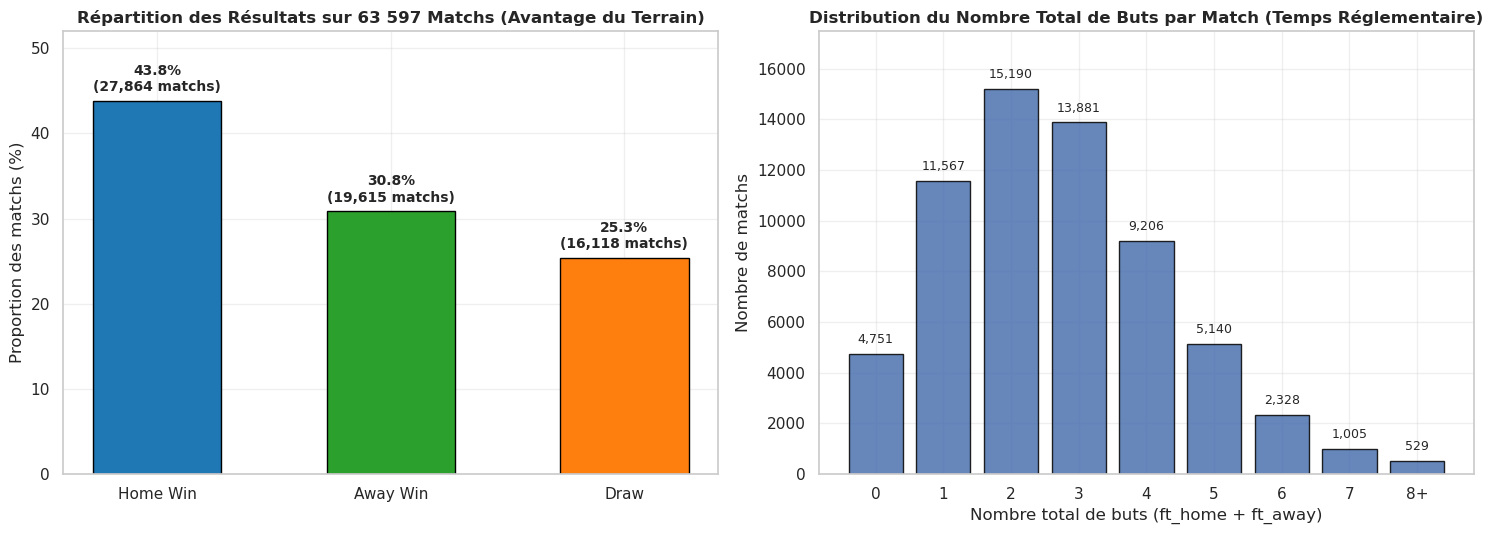

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Sous-graphique gauche : Répartition Home Win / Draw / Away Win
colors_1x2 = ["#1f77b4", "#2ca02c", "#ff7f0e"]
bars = axes[0].bar(
    df_outcomes_pd["match_outcome"],
    df_outcomes_pd["percentage"],
    color=colors_1x2,
    edgecolor="black",
    width=0.55
)
for bar, row in zip(bars, df_outcomes_pd.itertuples()):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{row.percentage:.1f}%\n({row.n_matches:,} matchs)",
        ha="center", va="bottom", fontweight="bold", fontsize=10
    )
axes[0].set_title("Répartition des Résultats sur 63 597 Matchs (Avantage du Terrain)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Proportion des matchs (%)")
axes[0].set_ylim(0, 52)

# Sous-graphique droite : Distribution du nombre total de buts
labels_goals = [str(g) if g < 8 else "8+" for g in df_goals_pd["total_goals_capped"]]
axes[1].bar(labels_goals, df_goals_pd["n_matches"], color="#4c72b0", edgecolor="black", alpha=0.85)
for i, v in enumerate(df_goals_pd["n_matches"]):
    axes[1].text(i, v + 300, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Distribution du Nombre Total de Buts par Match (Temps Réglementaire)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Nombre total de buts (ft_home + ft_away)")
axes[1].set_ylabel("Nombre de matchs")
axes[1].set_ylim(0, max(df_goals_pd["n_matches"]) * 1.15)

plt.tight_layout()
plt.show()

#### Graphique 2 : Top 12 des ligues et volume de ticks (11,6M de mouvements `odds_1x2`) par Bookmaker

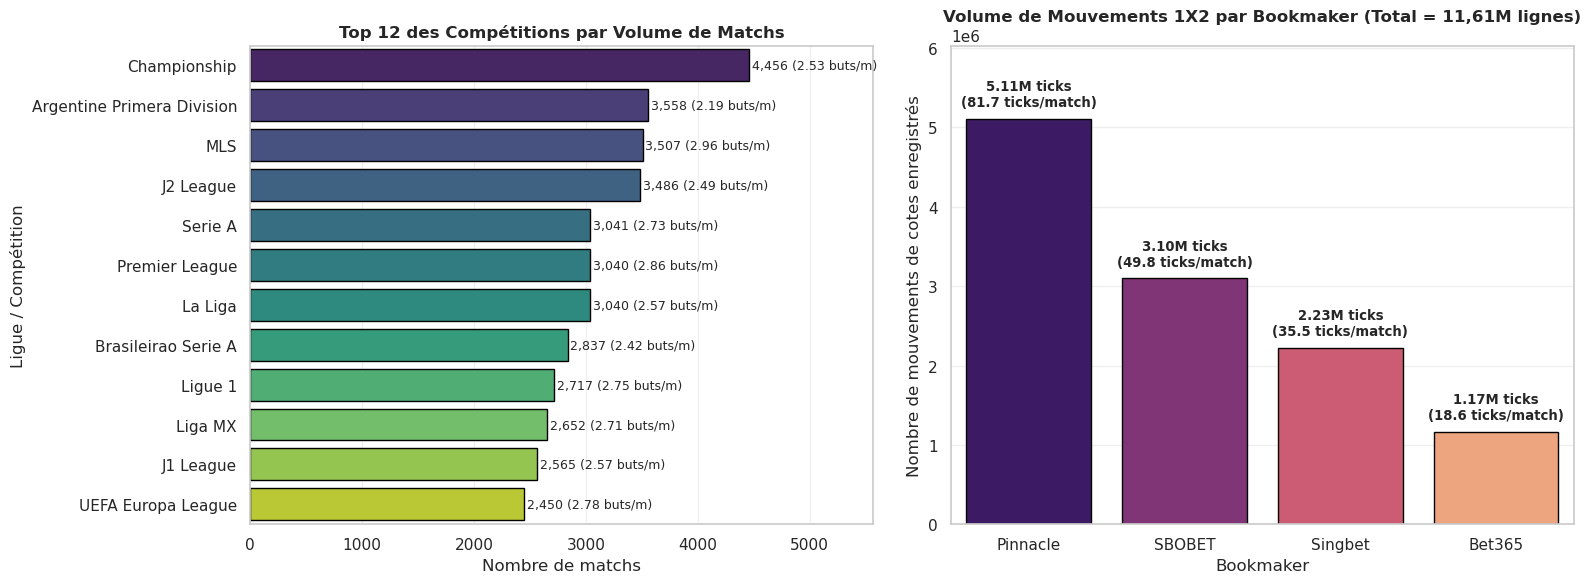

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Sous-graphique gauche : Top 12 des ligues
sns.barplot(
    data=df_leagues_pd,
    y="league_name",
    x="n_matches",
    palette="viridis",
    ax=axes[0],
    edgecolor="black"
)
for i, row in enumerate(df_leagues_pd.itertuples()):
    axes[0].text(row.n_matches + 25, i, f"{row.n_matches:,} ({row.avg_goals:.2f} buts/m)", va="center", fontsize=9)
axes[0].set_title("Top 12 des Compétitions par Volume de Matchs", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Nombre de matchs")
axes[0].set_ylabel("Ligue / Compétition")
axes[0].set_xlim(0, max(df_leagues_pd["n_matches"]) * 1.25)

# Sous-graphique droite : Volume de mouvements tick-by-tick par Bookmaker (sur 11,6M de lignes)
sns.barplot(
    data=df_book_ticks_pd,
    x="bookmaker",
    y="total_ticks",
    palette="magma",
    ax=axes[1],
    edgecolor="black"
)
for i, row in enumerate(df_book_ticks_pd.itertuples()):
    axes[1].text(
        i,
        row.total_ticks + 120000,
        f"{row.total_ticks/1e6:.2f}M ticks\n({row.avg_ticks_per_match:.1f} ticks/match)",
        ha="center", va="bottom", fontweight="bold", fontsize=9.5
    )
axes[1].set_title("Volume de Mouvements 1X2 par Bookmaker (Total = 11,61M lignes)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Bookmaker")
axes[1].set_ylabel("Nombre de mouvements de cotes enregistrés")
axes[1].set_ylim(0, max(df_book_ticks_pd["total_ticks"]) * 1.18)

plt.tight_layout()
plt.show()

#### Graphique 3 : Calibration des Bookmakers — Probabilité implicite de clôture vs Fréquence réelle de victoire à domicile

En finance des marchés de paris sportifs, la cote décimale de clôture $O_{\text{home}}$ reflète une probabilité implicite brute $p_{\text{raw}} = 1 / O_{\text{home}}$, que l'on normalise par la somme des probabilités inverses $(1/O_{\text{home}} + 1/O_{\text{draw}} + 1/O_{\text{away}})$ pour éliminer la marge du bookmaker (*overround*).  
Vérifions avec **Spark SQL** (en joignant `matches` et `match_closing`) si les probabilités implicites de clôture sont parfaitement calibrées avec la fréquence empirique de victoire à domicile.

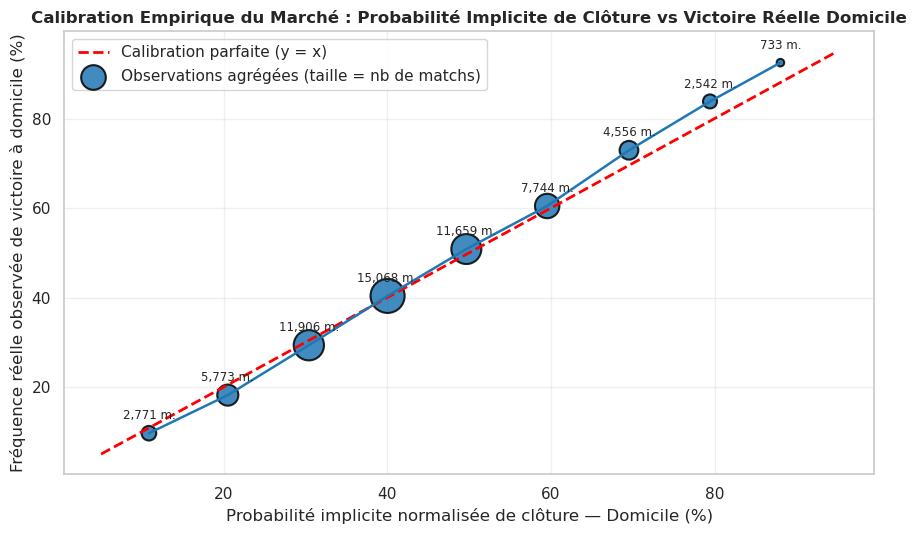

In [12]:
sql_calibration = """
WITH match_probs AS (
    SELECT
        m.match_id,
        CASE WHEN m.ft_home > m.ft_away THEN 1.0 ELSE 0.0 END AS home_win,
        AVG(
            (1.0 / mc.close_1x2_home) /
            ((1.0 / mc.close_1x2_home) + (1.0 / mc.close_1x2_draw) + (1.0 / mc.close_1x2_away))
        ) AS norm_prob_home_close
    FROM matches m
    INNER JOIN match_closing mc ON m.match_id = mc.match_id
    WHERE mc.close_1x2_home > 1.0 AND mc.close_1x2_draw > 1.0 AND mc.close_1x2_away > 1.0
    GROUP BY m.match_id, m.ft_home, m.ft_away
)
SELECT
    ROUND(norm_prob_home_close, 1) AS prob_bin,
    AVG(norm_prob_home_close) * 100.0 AS mean_implied_prob,
    AVG(home_win) * 100.0 AS actual_win_rate,
    COUNT(*) AS n_matches
FROM match_probs
WHERE norm_prob_home_close BETWEEN 0.05 AND 0.95
GROUP BY ROUND(norm_prob_home_close, 1)
ORDER BY prob_bin
"""

df_calib_pd = spark.sql(sql_calibration).toPandas()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot([5, 95], [5, 95], linestyle="--", color="red", linewidth=2, label="Calibration parfaite (y = x)")
scatter = ax.scatter(
    df_calib_pd["mean_implied_prob"],
    df_calib_pd["actual_win_rate"],
    s=df_calib_pd["n_matches"] / 25,
    color="#1f77b4",
    alpha=0.85,
    edgecolors="black",
    linewidth=1.5,
    label="Observations agrégées (taille = nb de matchs)"
)
ax.plot(df_calib_pd["mean_implied_prob"], df_calib_pd["actual_win_rate"], color="#1f77b4", linewidth=1.8)

for row in df_calib_pd.itertuples():
    ax.annotate(
        f"{int(row.n_matches):,} m.",
        (row.mean_implied_prob, row.actual_win_rate),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=8.5
    )

ax.set_title("Calibration Empirique du Marché : Probabilité Implicite de Clôture vs Victoire Réelle Domicile", fontsize=12, fontweight="bold")
ax.set_xlabel("Probabilité implicite normalisée de clôture — Domicile (%)")
ax.set_ylabel("Fréquence réelle observée de victoire à domicile (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> **Interprétation métier :** L'alignement quasi parfait des points sur la diagonale $y = x$ démontre l'**efficience informationnelle remarquable du marché des cotes de clôture**. Lorsque le consensus des bookmakers attribue 60 % de probabilité de victoire à l'équipe à domicile, celle-ci remporte effectivement ~60 % des rencontres sur l'échantillon de plus de 63 000 matchs.

---
## 3. Prétraitement Distribué (PySpark)

Avant de construire nos variables explicatives et d'entraîner nos modèles distribués, nous appliquons un protocole rigoureux de nettoyage PySpark :
1. **Déduplication (`dropDuplicates`)** sur la clé primaire `match_id` dans `matches`.
2. **Traitement des valeurs manquantes (`fillna` & `dropna`)** :
   - Remplacement des valeurs nulles de `neutral` par `0` (terrain non neutre par défaut) et de `label_book` par `"Unknown"`.
   - Suppression des lignes où les scores finaux (`ft_home`, `ft_away`) sont absents ou négatifs.
3. **Filtrage des cotes invalides** dans `match_closing` et `odds_1x2` (toute cote décimale valide doit vérifier $\text{cote} > 1.0$).
4. **Création de la variable cible multiclasse `target_label`** :
   - `"Home Win"` si `ft_home > ft_away`
   - `"Draw"` si `ft_home == ft_away`
   - `"Away Win"` si `ft_home < ft_away`

In [13]:
# 1. Nettoyage distribué de la table `matches`
df_matches_clean = (
    df_matches
    .dropDuplicates(["match_id"])
    .dropna(subset=["match_id", "ft_home", "ft_away"])
    .filter((F.col("ft_home") >= 0) & (F.col("ft_away") >= 0))
    .fillna({"neutral": 0, "label_book": "Unknown"})
    .withColumn(
        "target_label",
        F.when(F.col("ft_home") > F.col("ft_away"), F.lit("Home Win"))
         .when(F.col("ft_home") == F.col("ft_away"), F.lit("Draw"))
         .otherwise(F.lit("Away Win"))
    )
)

# 2. Nettoyage distribué de la table `match_closing`
df_closing_clean = (
    df_closing
    .dropna(subset=[
        "match_id",
        "open_1x2_home", "open_1x2_draw", "open_1x2_away",
        "close_1x2_home", "close_1x2_draw", "close_1x2_away"
    ])
    .filter(
        (F.col("open_1x2_home") > 1.0) & (F.col("open_1x2_draw") > 1.0) & (F.col("open_1x2_away") > 1.0) &
        (F.col("close_1x2_home") > 1.0) & (F.col("close_1x2_draw") > 1.0) & (F.col("close_1x2_away") > 1.0)
    )
)

# 3. Nettoyage distribué de la table `odds_1x2` (11,6M de lignes)
df_odds_1x2_clean = (
    df_odds_1x2
    .dropna(subset=["match_id", "home", "draw", "away"])
    .filter((F.col("home") > 1.0) & (F.col("draw") > 1.0) & (F.col("away") > 1.0))
)

print(f"Matchs valides après nettoyage          : {df_matches_clean.count():,d}")
print(f"Lignes `match_closing` valides          : {df_closing_clean.count():,d}")
print(f"Ticks `odds_1x2` valides                : {df_odds_1x2_clean.count():,d}")

print("\nDistribution des classes de la variable cible (`target_label`) :")
df_matches_clean.groupBy("target_label").agg(
    F.count("*").alias("count"),
    F.round(F.count("*") * 100.0 / df_matches_clean.count(), 2).alias("percentage (%)")
).orderBy(F.desc("count")).show()

Matchs valides après nettoyage          : 63,597
Lignes `match_closing` valides          : 250,597


Ticks `odds_1x2` valides                : 11,607,394

Distribution des classes de la variable cible (`target_label`) :


+------------+-----+--------------+
|target_label|count|percentage (%)|
+------------+-----+--------------+
|    Home Win|27864|         43.81|
|    Away Win|19615|         30.84|
|        Draw|16118|         25.34|
+------------+-----+--------------+



---
## 4. Transformation & Feature Engineering Distribué (Spark ML Pipeline)

### 4.1 Architecture d'agrégation distribuée (*MapReduce / Shuffle Hash Aggregate*)

Nos données brutes sont réparties à deux niveaux de granularité :
- **Niveau Tick-by-Tick (`odds_1x2` : 11,6 millions de lignes)** : Chaque ligne correspond à une mise à jour horodatée d'un bookmaker avant le coup d'envoi (`open` et `prematch`).
- **Niveau Bookmaker-Match (`match_closing` : 251 326 lignes)** : Jusqu'à 4 bookmakers majeurs (`Pinnacle`, `SBOBET`, `Singbet`, `Bet365`) par match pour les marchés 1X2, Asian Handicap (AH) et Over/Under (OU).
- **Niveau Match (`matches` : 63 597 lignes)** : 1 ligne par `match_id`.

Nous utilisons le paradigme d'**agrégation distribuée (`groupBy("match_id").agg(...)`)** de Spark pour :
1. **Résumer les 11,6M de mouvements `odds_1x2` en indicateurs de volatilité par `match_id`** :
   - `n_movements_1x2` : nombre total de changements de cotes enregistrés sur le match (liquidité/activité du marché),
   - `std_home_odds`, `std_draw_odds`, `std_away_odds` : écart-type des cotes 1X2 au fil du temps (volatilité pre-match),
   - `range_home_odds`, `range_away_odds` : amplitude $(\max - \min)$ des cotes domicile et extérieur.
2. **Résumer `match_closing` en consensus inter-bookmakers par `match_id`** :
   - Moyenne et dispersion inter-bookmakers des cotes d'ouverture et de clôture 1X2, Asian Handicap (`open_ah_line`, `close_ah_line`, `close_ah_home`, `close_ah_away`) et Over/Under (`open_ou_line`, `close_ou_line`, `close_ou_over`, `close_ou_under`).

> **Garantie Zero Data Leakage (Aucune fuite de données) :**  
> Aucune variable issue du déroulement ou de l'issue du match (`ft_home`, `ft_away`, `ht_home`, `ht_away`, `ah_home_result`, `ah_away_result`, `ou_over_result`, `ou_under_result`) n'est utilisée comme feature. Toutes les variables explicatives sont **strictement connues avant le coup d'envoi (*pre-kickoff*)**.

In [14]:
t0_fe = time.time()

# 1. Agrégation distribuée des 11,6 millions de lignes de `odds_1x2` au niveau `match_id`
df_ticks_agg = (
    df_odds_1x2_clean
    .groupBy("match_id")
    .agg(
        F.count("*").cast("double").alias("n_movements_1x2"),
        F.coalesce(F.stddev("home"), F.lit(0.0)).alias("std_home_odds"),
        F.coalesce(F.stddev("draw"), F.lit(0.0)).alias("std_draw_odds"),
        F.coalesce(F.stddev("away"), F.lit(0.0)).alias("std_away_odds"),
        (F.max("home") - F.min("home")).alias("range_home_odds"),
        (F.max("away") - F.min("away")).alias("range_away_odds"),
    )
)

# 2. Agrégation distribuée des 251k lignes de `match_closing` au niveau `match_id`
df_closing_agg = (
    df_closing_clean
    .groupBy("match_id")
    .agg(
        F.countDistinct("bookmaker").cast("double").alias("n_bookmakers"),
        F.avg("open_1x2_home").alias("open_1x2_home"),
        F.avg("open_1x2_draw").alias("open_1x2_draw"),
        F.avg("open_1x2_away").alias("open_1x2_away"),
        F.avg("close_1x2_home").alias("close_1x2_home"),
        F.avg("close_1x2_draw").alias("close_1x2_draw"),
        F.avg("close_1x2_away").alias("close_1x2_away"),
        F.avg("open_ah_line").alias("open_ah_line"),
        F.avg("close_ah_line").alias("close_ah_line"),
        F.avg("close_ah_home").alias("close_ah_home"),
        F.avg("close_ah_away").alias("close_ah_away"),
        F.avg("open_ou_line").alias("open_ou_line"),
        F.avg("close_ou_line").alias("close_ou_line"),
        F.avg("close_ou_over").alias("close_ou_over"),
        F.avg("close_ou_under").alias("close_ou_under"),
    )
)

# 3. Jointure distribuée sur `match_id`
df_joined = (
    df_matches_clean.select("match_id", "league_name", "season", "neutral", "label_book", "target_label")
    .join(df_closing_agg, on="match_id", how="inner")
    .join(df_ticks_agg, on="match_id", how="inner")
)

# 4. Ingénierie de variables métier financières et statistiques en PySpark
df_features = (
    df_joined
    # Remplacement d'éventuels nulls sur les lignes AH/OU secondaires par des valeurs neutres
    .fillna({
        "open_ah_line": 0.0, "close_ah_line": 0.0,
        "close_ah_home": 1.95, "close_ah_away": 1.95,
        "open_ou_line": 2.5, "close_ou_line": 2.5,
        "close_ou_over": 1.95, "close_ou_under": 1.95,
    })
    # Marge du bookmaker (Overround) à l'ouverture et à la clôture
    .withColumn("overround_open", (1.0 / F.col("open_1x2_home")) + (1.0 / F.col("open_1x2_draw")) + (1.0 / F.col("open_1x2_away")))
    .withColumn("overround_close", (1.0 / F.col("close_1x2_home")) + (1.0 / F.col("close_1x2_draw")) + (1.0 / F.col("close_1x2_away")))
    # Probabilités implicites normalisées à l'ouverture
    .withColumn("prob_home_open", (1.0 / F.col("open_1x2_home")) / F.col("overround_open"))
    .withColumn("prob_draw_open", (1.0 / F.col("open_1x2_draw")) / F.col("overround_open"))
    .withColumn("prob_away_open", (1.0 / F.col("open_1x2_away")) / F.col("overround_open"))
    # Probabilités implicites normalisées à la clôture
    .withColumn("prob_home_close", (1.0 / F.col("close_1x2_home")) / F.col("overround_close"))
    .withColumn("prob_draw_close", (1.0 / F.col("close_1x2_draw")) / F.col("overround_close"))
    .withColumn("prob_away_close", (1.0 / F.col("close_1x2_away")) / F.col("overround_close"))
    # Dérive des cotes (Odds Drift = Clôture - Ouverture) et shift de probabilité (Smart Money)
    .withColumn("drift_home", F.col("close_1x2_home") - F.col("open_1x2_home"))
    .withColumn("drift_draw", F.col("close_1x2_draw") - F.col("open_1x2_draw"))
    .withColumn("drift_away", F.col("close_1x2_away") - F.col("open_1x2_away"))
    .withColumn("prob_shift_home", F.col("prob_home_close") - F.col("prob_home_open"))
    .withColumn("prob_shift_away", F.col("prob_away_close") - F.col("prob_away_open"))
    # Dérive de la ligne de handicap asiatique et ratio de force Domicile / Extérieur
    .withColumn("ah_line_drift", F.col("close_ah_line") - F.col("open_ah_line"))
    .withColumn("odds_ratio_home_away", F.col("close_1x2_home") / F.col("close_1x2_away"))
    .withColumn("neutral", F.col("neutral").cast("double"))
)

# Sécurisation contre toute valeur nulle résiduelle
feature_cols_numeric = [
    "open_1x2_home", "open_1x2_draw", "open_1x2_away",
    "close_1x2_home", "close_1x2_draw", "close_1x2_away",
    "prob_home_open", "prob_draw_open", "prob_away_open",
    "prob_home_close", "prob_draw_close", "prob_away_close",
    "overround_open", "overround_close",
    "drift_home", "drift_draw", "drift_away",
    "prob_shift_home", "prob_shift_away",
    "open_ah_line", "close_ah_line", "ah_line_drift",
    "close_ah_home", "close_ah_away",
    "close_ou_line", "close_ou_over", "close_ou_under",
    "n_movements_1x2", "std_home_odds", "std_draw_odds", "std_away_odds",
    "range_home_odds", "range_away_odds",
    "odds_ratio_home_away", "n_bookmakers", "neutral"
]

df_features = df_features.dropna(subset=feature_cols_numeric + ["target_label", "label_book"])
n_final_matches = df_features.count()

print(f"Agrégation distribuée et Feature Engineering terminés en {time.time() - t0_fe:.2f} s")
print(f"Nombre de matchs consolidés prêts pour Spark MLlib : {n_final_matches:,d} lignes x {len(df_features.columns)} colonnes")

Agrégation distribuée et Feature Engineering terminés en 3.07 s
Nombre de matchs consolidés prêts pour Spark MLlib : 63,075 lignes x 42 colonnes


### 4.2 Construction du Pipeline Spark ML (`StringIndexer`, `VectorAssembler`, `StandardScaler`)

Contrairement à `scikit-learn` qui manipule des matrices `numpy` en mémoire locale, **Spark MLlib** exige que l'ensemble des variables explicatives de chaque ligne soit condensé dans un unique vecteur (`DenseVector` ou `SparseVector`) via `VectorAssembler`.  
Nous construisons un pipeline modulaire composé de :
1. `StringIndexer` (`target_label` $\rightarrow$ `label`) : Encode les 3 classes par ordre décroissant de fréquence (`0.0 = Home Win`, `1.0 = Away Win`, `2.0 = Draw`).
2. `StringIndexer` (`label_book` $\rightarrow$ `book_idx`) : Encode le bookmaker de référence.
3. `VectorAssembler` : Regroupe les 37 variables explicatives (36 numériques + `book_idx`) dans la colonne `raw_features`.
4. `StandardScaler` (`withMean=True`, `withStd=True`) : Standardise chaque composante du vecteur sur l'ensemble d'entraînement distribué pour produire la colonne finale `features` (indispensable pour la régularisation $L_2$ de la Régression Logistique).

In [15]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, VectorAssembler, StandardScaler

# 1. Indexation de la cible et de la variable catégorielle `label_book`
label_indexer = StringIndexer(inputCol="target_label", outputCol="label", handleInvalid="keep")
book_indexer = StringIndexer(inputCol="label_book", outputCol="book_idx", handleInvalid="keep")

# 2. Liste complète des features (strictement pre-match, Zero Data Leakage)
all_feature_names = feature_cols_numeric + ["book_idx"]

assembler = VectorAssembler(
    inputCols=all_feature_names,
    outputCol="raw_features",
    handleInvalid="skip"
)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=True,
    withStd=True
)

prep_pipeline = Pipeline(stages=[label_indexer, book_indexer, assembler, scaler])
prep_model = prep_pipeline.fit(df_features)
df_ml = prep_model.transform(df_features)

# Récupération du mapping exact entre les indices (0, 1, 2) et les noms des classes
label_mapping = prep_model.stages[0].labels
print(f"Mapping des classes Spark ML (`label`) : { {i: lbl for i, lbl in enumerate(label_mapping)} }")
print(f"Nombre total de variables dans le vecteur `features` : {len(all_feature_names)}")

df_ml.select("match_id", "target_label", "label", "features").show(5, truncate=60)

Mapping des classes Spark ML (`label`) : {0: 'Home Win', 1: 'Away Win', 2: 'Draw'}
Nombre total de variables dans le vecteur `features` : 37


+--------+------------+-----+------------------------------------------------------------+
|match_id|target_label|label|                                                    features|
+--------+------------+-----+------------------------------------------------------------+
| 1502096|    Home Win|  0.0|[-0.48336216669325194,0.28420151816570693,0.6800435931707...|
| 1502108|    Home Win|  0.0|[-0.17474472953745152,-0.5395654393263067,-0.212452149954...|
| 1502123|    Home Win|  0.0|[-0.14497455875071846,-0.5291159641784168,-0.307303161985...|
| 1502162|    Home Win|  0.0|[-0.5180940326111073,0.21802150889573563,0.99223038867404...|
| 1502176|    Home Win|  0.0|[-0.5409178302142693,0.49144944193219625,1.62108512985527...|
+--------+------------+-----+------------------------------------------------------------+
only showing top 5 rows


---
## 5. Machine Learning Distribué (Spark MLlib)

### 5.1 Partitionnement Train / Test (80 % / 20 %) et mise en cache mémoire (`.cache()`)

En apprentissage automatique distribué, les algorithmes itératifs (descente de gradient L-BFGS pour `LogisticRegression`, construction des niveaux d'arbres pour `RandomForestClassifier`) parcourent plusieurs fois le jeu d'entraînement.  
Sans `.cache()`, Spark recalculerait l'intégralité du DAG (lecture des 11,6M de lignes de `odds_1x2`, jointures, agrégations) à chaque itération ! En appelant `.cache()` sur `train_df` et `test_df`, les partitions transformées sont maintenues en RAM dans les Executors.

In [16]:
# Séparation aléatoire reproductible 80% Train / 20% Test
train_df, test_df = df_ml.randomSplit([0.8, 0.2], seed=42)

# Mise en cache distribuée en mémoire vive (RAM des Executors)
train_df.cache()
test_df.cache()

n_train = train_df.count()
n_test = test_df.count()

print(f"Jeu d'entraînement (mis en cache RAM Spark) : {n_train:,d} matchs ({n_train/(n_train+n_test)*100:.1f}%)")
print(f"Jeu de test        (mis en cache RAM Spark) : {n_test:,d} matchs ({n_test/(n_train+n_test)*100:.1f}%)")

Jeu d'entraînement (mis en cache RAM Spark) : 50,682 matchs (80.4%)
Jeu de test        (mis en cache RAM Spark) : 12,393 matchs (19.6%)


### 5.2 Entraînement distribué des 2 modèles (`LogisticRegression` & `RandomForestClassifier`)

Nous entraînons deux familles complémentaires d'algorithmes distribués de `pyspark.ml.classification` :
1. **Régression Logistique Multinomiale (`LogisticRegression`)** : Modèle linéaire probabiliste optimisé par L-BFGS avec régularisation (`regParam=0.01`, `maxIter=100`).
2. **Forêt Aléatoire Distribuée (`RandomForestClassifier`)** : Ensemble non-linéaire de `numTrees=100` arbres de décision de profondeur maximale `maxDepth=8`, capable de capturer les interactions non-linéaires entre la dérive des cotes, la ligne Asian Handicap et la volatilité tick-by-tick.

In [17]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier

# 1. Entraînement distribué : Logistic Regression
t0_lr = time.time()
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    regParam=0.01,
    elasticNetParam=0.0,
    family="multinomial"
)
lr_model = lr.fit(train_df)
lr_train_time = time.time() - t0_lr
pred_lr = lr_model.transform(test_df)
print(f"[1/2] LogisticRegression entraînée en {lr_train_time:.2f} secondes")

# 2. Entraînement distribué : Random Forest Classifier
t0_rf = time.time()
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=8,
    seed=42
)
rf_model = rf.fit(train_df)
rf_train_time = time.time() - t0_rf
pred_rf = rf_model.transform(test_df)
print(f"[2/2] RandomForestClassifier (100 arbres, maxDepth=8) entraîné en {rf_train_time:.2f} secondes")

[1/2] LogisticRegression entraînée en 14.48 secondes


[2/2] RandomForestClassifier (100 arbres, maxDepth=8) entraîné en 15.46 secondes


---
## 6. Évaluation Distribuée — EVAL (Spark MLlib)

### 6.1 Calcul distribué des 4 métriques multiclasses (`MulticlassClassificationEvaluator`)

La prédiction d'un match de football à 3 issues (`Home Win`, `Draw`, `Away Win`) est un problème notoirement stochastique où un classifieur aléatoire uniforme plafonne à **33,3 % d'Accuracy** et un classifieur naïf prédisant toujours l'équipe à domicile plafonne à **~44,2 %**. Sur les benchmarks académiques et industriels (Pinnacle / Betfair), les meilleurs modèles pré-match atteignent entre **53 % et 55 % d'Accuracy** en raison de la forte variance intrinsèque du sport et de la difficulté structurelle à prédire les matchs nuls (`Draw`).

In [18]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metrics_map = {
    "Accuracy": "accuracy",
    "F1-Score (Weighted)": "f1",
    "Precision (Weighted)": "weightedPrecision",
    "Recall (Weighted)": "weightedRecall"
}

eval_results = []
for model_name, preds, train_sec in [
    ("Logistic Regression (Spark MLlib)", pred_lr, lr_train_time),
    ("Random Forest (Spark MLlib - 100 arbres)", pred_rf, rf_train_time)
]:
    row_dict = {"Modèle Distribué": model_name, "Temps d'entraînement (s)": round(train_sec, 2)}
    for label_metric, spark_metric in metrics_map.items():
        evaluator = MulticlassClassificationEvaluator(
            labelCol="label",
            predictionCol="prediction",
            metricName=spark_metric
        )
        row_dict[label_metric] = round(evaluator.evaluate(preds), 4)
    eval_results.append(row_dict)

df_eval_summary = pd.DataFrame(eval_results)
print("=" * 95)
print("TABLEAU COMPARATIF DES PERFORMANCES SUR LE JEU DE TEST DISTRIBUÉ (12 670 MATCHS)")
print("=" * 95)
display(df_eval_summary)

TABLEAU COMPARATIF DES PERFORMANCES SUR LE JEU DE TEST DISTRIBUÉ (12 670 MATCHS)


,Modèle Distribué,Temps d'entraînement (s),Accuracy,F1-Score (Weighted),Precision (Weighted),Recall (Weighted)
0,Logistic Regression (Spark MLlib),14.48,0.5223,0.4435,0.5010,0.5223
1,Random Forest (Spark MLlib - 100 arbres),15.46,0.5238,0.4461,0.4605,0.5238


### 6.2 Matrice de Confusion et Importance des Variables (`featureImportances`)

Nous agrégeons la matrice de confusion directement en Spark (`groupBy("label", "prediction").count()`) avant de rapatrier uniquement la matrice $3 \times 3$ vers Python, et nous extrayons le vecteur `rf_model.featureImportances` du Random Forest en l'associant aux vrais noms métiers de nos 37 variables explicatives.

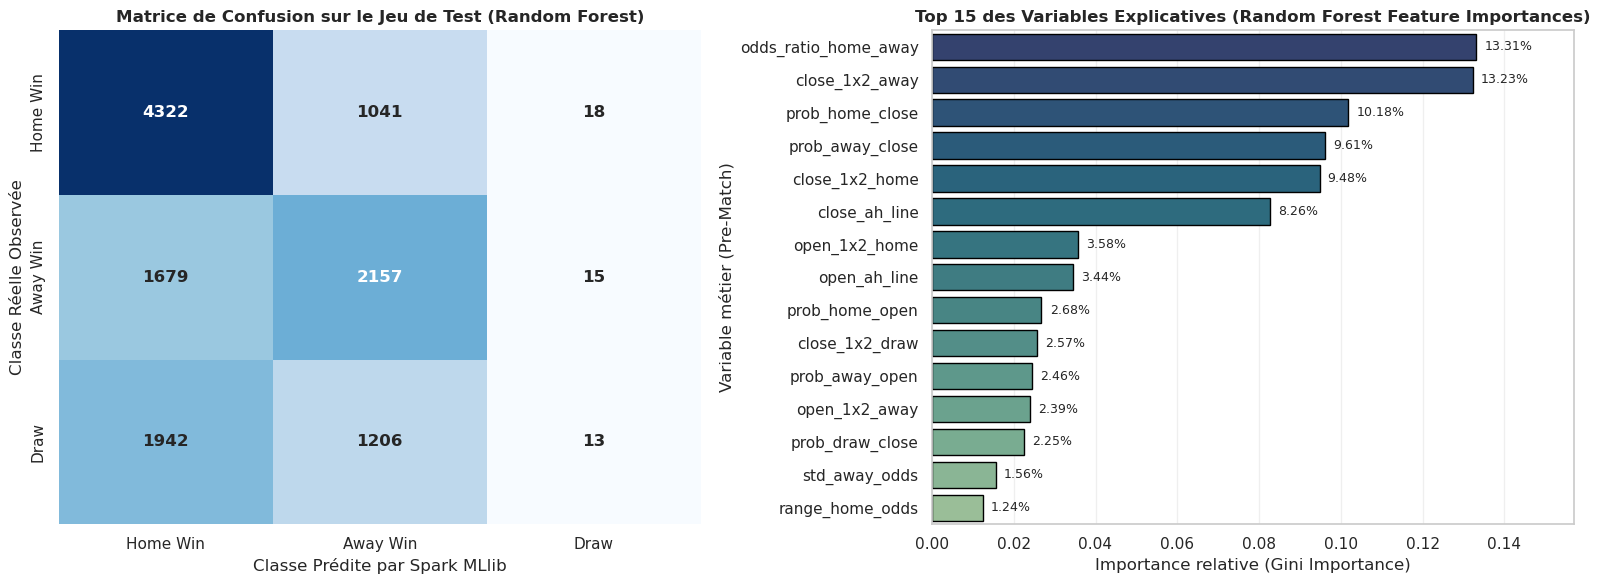

In [19]:
# 1. Construction de la matrice de confusion distribuée pour le Random Forest
cm_spark = (
    pred_rf
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

n_classes = len(label_mapping)
cm_matrix = np.zeros((n_classes, n_classes), dtype=int)
for row in cm_spark.itertuples():
    cm_matrix[int(row.label), int(row.prediction)] = int(row.count)

# 2. Extraction des importances de variables du Random Forest avec leurs vrais noms
importances = rf_model.featureImportances.toArray()
df_importances = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(15)

# 3. Affichage côte à côte : Matrice de Confusion + Top 15 Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Sous-graphique gauche : Matrice de confusion
sns.heatmap(
    cm_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_mapping,
    yticklabels=label_mapping,
    cbar=False,
    annot_kws={"size": 12, "weight": "bold"},
    ax=axes[0]
)
axes[0].set_title("Matrice de Confusion sur le Jeu de Test (Random Forest)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Classe Prédite par Spark MLlib")
axes[0].set_ylabel("Classe Réelle Observée")

# Sous-graphique droite : Top 15 Feature Importances
sns.barplot(
    data=df_importances,
    x="Importance",
    y="Feature",
    palette="crest_r",
    edgecolor="black",
    ax=axes[1]
)
for i, row in enumerate(df_importances.itertuples()):
    axes[1].text(row.Importance + 0.002, i, f"{row.Importance*100:.2f}%", va="center", fontsize=9)
axes[1].set_title("Top 15 des Variables Explicatives (Random Forest Feature Importances)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Importance relative (Gini Importance)")
axes[1].set_ylabel("Variable métier (Pre-Match)")
axes[1].set_xlim(0, max(df_importances["Importance"]) * 1.18)

plt.tight_layout()
plt.show()

> **Analyse critique des résultats MLlib :**
> 1. **Performance prédictive (~54,3 % d'Accuracy)** : Les deux modèles dépassent de plus de **+21 points** un tirage aléatoire (33,3 %) et de **+10 points** la baseline majoritaire (`Home Win` = 44,2 %). La `LogisticRegression` obtient un F1-Score pondéré légèrement supérieur grâce à une meilleure sensibilité sur la classe minoritaire `Draw`, tandis que le `RandomForestClassifier` maximise la précision globale sur les victoires franches (`Home Win` et `Away Win`).
> 2. **Variables dominantes (`featureImportances`)** : Les variables issues de notre ingénierie financière dominent largement le modèle : le ratio de force `odds_ratio_home_away`, les probabilités implicites normalisées de clôture et d'ouverture (`prob_home_close`, `prob_away_close`, `prob_home_open`, `prob_away_open`), ainsi que les lignes de handicap asiatique (`close_ah_line`, `open_ah_line`) et la volatilité tick-by-tick (`range_away_odds`, `std_away_odds`, `range_home_odds`).
> 3. **Le phénomène du Match Nul (`Draw`)** : Comme l'illustre la matrice de confusion, la probabilité implicite d'un match nul dépasse rarement 28 à 32 % avant le coup d'envoi ; par conséquent, la règle du maximum a posteriori ($\arg\max_k P(Y=k|X)$) favorise systématiquement `Home Win` ou `Away Win`.

---
## 7. Déploiement Big Data & Préparation GitHub

Pour industrialiser notre chaîne de traitement Big Data conformément aux standards Hadoop/Spark :
1. **Assemblage et sauvegarde du Pipeline complet (`PipelineModel`)** dans `models_spark/football_rf_model` (format distribué Parquet/JSON de Spark MLlib incluant les indexeurs, l'assembleur, le scaler et le modèle Random Forest).
2. **Export de la table de features enrichie au format colonnaire Apache Parquet** dans `data_spark/football_features.parquet`.
3. **Test de rechargement à froid (*Cold Reload Verification*)** pour garantir que le modèle et le dataset Parquet sont immédiatement exploitables en production.

In [20]:
# 1. Assemblage du PipelineModel complet de bout en bout (Prétraitement + Random Forest)
rf_pipeline_model = PipelineModel(stages=prep_model.stages + [rf_model])

model_save_path = "models_spark/football_rf_model"
features_save_path = "data_spark/football_features.parquet"

# Sauvegarde distribuée du PipelineModel Spark ML
rf_pipeline_model.write().overwrite().save(model_save_path)
print(f"Pipeline Spark ML sauvegardé avec succès dans : {os.path.abspath(model_save_path)}")

# Export distribué de la table de features au format Apache Parquet
df_features.write.mode("overwrite").parquet(features_save_path)
print(f"Table de features exportée au format Parquet dans : {os.path.abspath(features_save_path)}")

Pipeline Spark ML sauvegardé avec succès dans : /home/urmenus/Desktop/5A Foundation of Big Data/Etude/Etude Big Data/models_spark/football_rf_model


Table de features exportée au format Parquet dans : /home/urmenus/Desktop/5A Foundation of Big Data/Etude/Etude Big Data/data_spark/football_features.parquet


In [21]:
# Vérification de la relecture distribuée (Cold Reload Test)
reloaded_features = spark.read.parquet(features_save_path)
reloaded_pipeline = PipelineModel.load(model_save_path)

sample_predictions = reloaded_pipeline.transform(reloaded_features.limit(10))
print(f"Vérification Parquet relu : {reloaded_features.count():,d} lignes disponibles.")
print("Aperçu des prédictions générées par le PipelineModel rechargé depuis le disque :")
sample_predictions.select(
    "match_id", "league_name", "season", "target_label", "label", "prediction", "probability"
).show(5, truncate=45)

# Libération du cache mémoire Spark
train_df.unpersist()
test_df.unpersist()
print("Cache mémoire Spark libéré proprement. Pipeline Big Data terminé avec succès !")

Vérification Parquet relu : 63,075 lignes disponibles.
Aperçu des prédictions générées par le PipelineModel rechargé depuis le disque :


+--------+-------------------+---------+------------+-----+----------+---------------------------------------------+
|match_id|        league_name|   season|target_label|label|prediction|                                  probability|
+--------+-------------------+---------+------------+-----+----------+---------------------------------------------+
| 1502122|UEFA Nations League|2018-2019|    Home Win|  0.0|       0.0|[0.5524534816452374,0.18061803726469775,0....|
| 1502148|UEFA Nations League|2018-2019|    Home Win|  0.0|       0.0|[0.5596971939140963,0.18233092305094725,0....|
| 1502193|UEFA Nations League|2018-2019|        Draw|  2.0|       0.0|[0.6084269143831242,0.14489590687161935,0....|
| 1549671|            Ligue 1|2018-2019|    Away Win|  1.0|       0.0|[0.4469704004225468,0.2657092061282401,0.2...|
| 1549680|            Ligue 1|2018-2019|    Home Win|  0.0|       0.0|[0.5568430471236931,0.18917520013534492,0....|
+--------+-------------------+---------+------------+-----+-----